In [1]:
# ============================================================
# NB02 - CELDA 1: VERIFICACIÓN DEL ENTORNO
#
# Objetivo:
#   1. Identificar el intérprete Python del notebook.
#   2. Verificar la versión de PyTorch.
#   3. Detectar si existe una GPU disponible.
#
# En VSCode local esperamos CPU.
# Posteriormente, en Google Colab esperamos GPU T4.
#
# Esta celda NO entrena ninguna red neuronal.
# ============================================================

import sys
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Python:", sys.version.split()[0])
print("Intérprete:", sys.executable)
print("PyTorch:", torch.__version__)
print("Dispositivo:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU: No disponible; ejecución local mediante CPU")

print("\nEstado: PASS - Entorno identificado correctamente.")

Python: 3.13.16
Intérprete: /usr/bin/python3
PyTorch: 2.11.0+cu130
Dispositivo: cuda
GPU: Tesla T4

Estado: PASS - Entorno identificado correctamente.


In [2]:
# ============================================================
# NB02 - CELDA 2: MODELO ENCODER-DECODER SIN SKIP CONNECTIONS
#
# Objetivo:
#   1. Construir nuestra CNN baseline para segmentar fisuras.
#   2. Reducir la resolución con el Encoder.
#   3. Recuperar la resolución con el Decoder.
#   4. Producir un logit por píxel: fondo o fisura.
#
# Arquitectura ligera para el entrenamiento piloto.
# NO utiliza conexiones skip.
# Esta celda NO entrena el modelo.
# ============================================================

import torch
import torch.nn as nn


# Bloque de dos convoluciones 3x3.
class BloqueConv(nn.Module):

    def __init__(self, canales_entrada, canales_salida):
        super().__init__()

        self.capas = nn.Sequential(
            nn.Conv2d(canales_entrada, canales_salida,
                      kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(canales_salida, canales_salida,
                      kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.capas(x)


# CNN Encoder-Decoder SIN conexiones skip.
class EncoderDecoder(nn.Module):

    def __init__(self):
        super().__init__()

        # ENCODER: extraer características y reducir resolución.
        self.encoder1 = BloqueConv(3, 16)
        self.pool1 = nn.MaxPool2d(2)

        self.encoder2 = BloqueConv(16, 32)
        self.pool2 = nn.MaxPool2d(2)

        # Cuello de botella: representación comprimida.
        self.bottleneck = BloqueConv(32, 64)

        # DECODER: recuperar progresivamente la resolución.
        self.up1 = nn.Upsample(scale_factor=2, mode="bilinear",
                               align_corners=False)
        self.decoder1 = BloqueConv(64, 32)

        self.up2 = nn.Upsample(scale_factor=2, mode="bilinear",
                               align_corners=False)
        self.decoder2 = BloqueConv(32, 16)

        # Una salida por píxel (logit).
        self.salida = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):

        # Encoder
        x = self.encoder1(x)
        x = self.pool1(x)

        x = self.encoder2(x)
        x = self.pool2(x)

        # Bottleneck
        x = self.bottleneck(x)

        # Decoder (sin concatenaciones skip)
        x = self.up1(x)
        x = self.decoder1(x)

        x = self.up2(x)
        x = self.decoder2(x)

        return self.salida(x)


# Instanciar el modelo en CPU o GPU, según disponibilidad.
modelo = EncoderDecoder().to(device)

# Contar parámetros entrenables.
parametros = sum(
    p.numel() for p in modelo.parameters()
    if p.requires_grad
)

print("Modelo:", modelo.__class__.__name__)
print(f"Parámetros entrenables: {parametros:,}")
print("Dispositivo:", device)

# Prueba de dimensiones usando una imagen ficticia.
# No utiliza datos del dataset ni actualiza pesos.
modelo.eval()

with torch.no_grad():
    entrada_prueba = torch.zeros(
        (1, 3, 416, 416), device=device
    )

    salida_prueba = modelo(entrada_prueba)

print("Entrada:", tuple(entrada_prueba.shape))
print("Salida: ", tuple(salida_prueba.shape))

assert salida_prueba.shape == (1, 1, 416, 416)

print("\nEstado: PASS - Arquitectura verificada.")

Modelo: EncoderDecoder
Parámetros entrenables: 106,753
Dispositivo: cuda
Entrada: (1, 3, 416, 416)
Salida:  (1, 1, 416, 416)

Estado: PASS - Arquitectura verificada.


In [3]:
# ============================================================
# NB02 - CELDA 3: FUNCIÓN DE PÉRDIDA BCE + DICE LOSS
#
# Objetivo:
#   1. Implementar Binary Cross-Entropy (BCE).
#   2. Implementar Dice Loss para segmentación binaria.
#   3. Combinar ambas pérdidas para enfrentar el desbalance
#      entre fisuras (aprox. 2%) y fondo (aprox. 98%).
#   4. Verificar que la función acepte la salida del modelo.
#
# Convención:
#   Máscara = 1: fisura
#   Máscara = 0: fondo
#
# Esta celda NO entrena el modelo ni modifica sus pesos.
# ============================================================

import torch
import torch.nn as nn


class BCEDiceLoss(nn.Module):

    def __init__(self, smooth=1.0):
        super().__init__()

        # BCEWithLogitsLoss aplica internamente sigmoid
        # de forma numéricamente estable.
        self.bce = nn.BCEWithLogitsLoss()

        # Constante que evita divisiones por cero.
        self.smooth = smooth

    def forward(self, logits, mascaras):

        # 1. Binary Cross-Entropy sobre todos los píxeles.
        loss_bce = self.bce(logits, mascaras)

        # 2. Convertir logits en probabilidades [0, 1].
        probabilidades = torch.sigmoid(logits)

        # 3. Calcular Dice por imagen.
        #    Se mantienen las dimensiones del batch.
        dimensiones = (1, 2, 3)

        interseccion = torch.sum(
            probabilidades * mascaras,
            dim=dimensiones
        )

        suma_predicciones = torch.sum(
            probabilidades,
            dim=dimensiones
        )

        suma_mascaras = torch.sum(
            mascaras,
            dim=dimensiones
        )

        dice = (
            2 * interseccion + self.smooth
        ) / (
            suma_predicciones + suma_mascaras + self.smooth
        )

        # Promedio de Dice Loss del minibatch.
        loss_dice = 1 - dice.mean()

        # 4. Pérdida total.
        loss_total = loss_bce + loss_dice

        return loss_total


# Instanciar la función de pérdida.
criterio = BCEDiceLoss().to(device)

# Prueba con la salida del modelo generada en la Celda 2.
# Crear una máscara ficticia con las mismas dimensiones.
mascara_prueba = torch.zeros_like(salida_prueba)

with torch.no_grad():
    perdida_prueba = criterio(
        salida_prueba,
        mascara_prueba
    )

print("Función de pérdida:", criterio.__class__.__name__)
print("Dimensión logits:", tuple(salida_prueba.shape))
print("Dimensión máscaras:", tuple(mascara_prueba.shape))
print("Pérdida de prueba:", round(perdida_prueba.item(), 6))

# Comprobar que la pérdida sea un número finito.
assert torch.isfinite(perdida_prueba).item()
assert perdida_prueba.ndim == 0

print("\nEstado: PASS - BCE + Dice Loss verificada.")

Función de pérdida: BCEDiceLoss
Dimensión logits: (1, 1, 416, 416)
Dimensión máscaras: (1, 1, 416, 416)
Pérdida de prueba: 1.614048

Estado: PASS - BCE + Dice Loss verificada.


In [4]:
# ============================================================
# NB02 - CELDA 4: CONFIGURACIÓN Y CARGA DEL DATASET PILOTO
#
# Objetivo:
#   1. Detectar si ejecutamos en VSCode o Google Colab.
#   2. Localizar el dataset piloto de Nicolás.
#   3. Crear los DataLoaders de TRAIN y VALIDACIÓN.
#   4. Preparar los parámetros del entrenamiento piloto.
#
# Esta celda NO entrena el modelo.
# ============================================================

import sys
from pathlib import Path

# Configuración inicial del entrenamiento.
BATCH_SIZE = 4
EPOCHS = 3
LEARNING_RATE = 1e-3
IMAGE_SIZE = 416

# Detectar Google Colab.
EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:

    from google.colab import drive
    drive.mount("/content/drive")

    # ZIP piloto almacenado en Google Drive.
    zip_piloto = Path(
        "/content/drive/MyDrive/Notebooks/Datasets/"
        "MIA-07_ExFinal_Fisuras/Entrega_Victor_Piloto_v1.zip"
    )

    assert zip_piloto.is_file(), (
        f"No se encontró el ZIP en Google Drive: {zip_piloto}"
    )

    # Extraer al disco temporal de Colab.
    import zipfile

    destino = Path("/content/datos_fisuras")
    destino.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_piloto) as archivo:
        archivo.extractall(destino)

    ruta_datos = (
        destino
        / "Entrega_Victor_Piloto_v1"
        / "piloto_v1"
    )

else:

    # Ejecución local desde la carpeta notebooks/.
    raiz_proyecto = Path.cwd().resolve().parent

    ruta_datos = (
        raiz_proyecto
        / "data"
        / "piloto"
        / "Entrega_Victor_Piloto_v1"
        / "piloto_v1"
    )

assert (ruta_datos / "lector_pytorch.py").is_file(), (
    f"No se encontró lector_pytorch.py en {ruta_datos}"
)

# Importar el lector preparado por Nicolás.
if str(ruta_datos) not in sys.path:
    sys.path.insert(0, str(ruta_datos))

from lector_pytorch import make_loaders

train_loader, val_loader = make_loaders(
    ruta_datos,
    batch_size=BATCH_SIZE,
    size=IMAGE_SIZE
)

print("Entorno:", "Google Colab" if EN_COLAB else "VSCode local")
print("Dataset:", ruta_datos)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Resolución:", IMAGE_SIZE)
print("Minibatches TRAIN:", len(train_loader))
print("Minibatches VAL:", len(val_loader))

assert len(train_loader) == 75
assert len(val_loader) == 13

print("\nEstado: PASS - Datos listos para entrenamiento.")

Mounted at /content/drive
Entorno: Google Colab
Dataset: /content/datos_fisuras/Entrega_Victor_Piloto_v1/piloto_v1
Batch size: 4
Epochs: 3
Learning rate: 0.001
Resolución: 416
Minibatches TRAIN: 75
Minibatches VAL: 13

Estado: PASS - Datos listos para entrenamiento.


In [6]:

# ============================================================
# NB02 - CELDA 5: ENTRENAMIENTO COMPLETO RECUPERABLE
#
# Objetivos:
#   1. Cargar el dataset COMPLETO de Nicolás desde Drive.
#   2. Entrenar el Encoder-Decoder congelado.
#   3. Medir Train Loss, Val Loss, Dice, IoU y tiempos.
#   4. Aplicar Early Stopping.
#   5. Guardar checkpoints BEST y LAST en Google Drive.
#   6. Recuperar automáticamente una sesión interrumpida.
#
# IMPORTANTE:
#   - Ejecutar en Google Colab con GPU T4.
#   - No usar TEST durante entrenamiento ni validación.
#   - Los checkpoints se guardan al FINAL de cada epoch.
# ============================================================

import os
import sys
import time
import random
import shutil
import zipfile
import importlib.util
from pathlib import Path
from datetime import datetime

import numpy as np
import torch

# ------------------------------------------------------------
# 1. CONFIGURACIÓN EXPERIMENTAL
# ------------------------------------------------------------

MAX_EPOCHS = 50
PATIENCE = 7
MIN_DELTA = 0.001

BATCH_SIZE = 4
IMAGE_SIZE = 416
LEARNING_RATE = 0.001
SEED = 20261026

NUM_TRAIN = 3717
NUM_VAL = 199

# Verificar que estamos utilizando la GPU.
if not torch.cuda.is_available():
    raise RuntimeError(
        "Se requiere GPU CUDA. Activar T4 en Google Colab."
    )

device = torch.device("cuda")

# ------------------------------------------------------------
# 2. RUTAS DEL DATASET COMPLETO Y CHECKPOINTS
# ------------------------------------------------------------

drive_base = Path(
    "/content/drive/MyDrive/Notebooks/Datasets/"
    "MIA-07_ExFinal_Fisuras"
)

zip_completo = (
    drive_base / "Entrega_Victor_Datos_Completos_v1.zip"
)

datos_locales = Path("/content/datos_fisuras_completo")

ruta_completo = (
    datos_locales / "Entrega_Victor_Datos_Completos_v1"
)

carpeta_checkpoints = (
    drive_base / "resultados" / "NB02_EncoderDecoder"
)

carpeta_checkpoints.mkdir(
    parents=True, exist_ok=True
)

checkpoint_last = (
    carpeta_checkpoints / "checkpoint_last.pt"
)

checkpoint_best = (
    carpeta_checkpoints / "checkpoint_best.pt"
)

assert zip_completo.is_file(), (
    f"No se encontró el ZIP completo: {zip_completo}"
)

# ------------------------------------------------------------
# 3. EXTRAER EL DATASET AL DISCO LOCAL DE COLAB
# ------------------------------------------------------------

# Solo extraer cuando la carpeta todavía no existe.
if not (ruta_completo / "lector_pytorch.py").is_file():

    print("Extrayendo dataset completo a /content...")

    datos_locales.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_completo, "r") as z:
        z.extractall(datos_locales)

    print("Extracción finalizada.")

assert (ruta_completo / "lector_pytorch.py").is_file()

# ------------------------------------------------------------
# 4. IMPORTAR EL LECTOR DEL DATASET COMPLETO
# ------------------------------------------------------------

# Importamos con un nombre específico para evitar reutilizar
# accidentalmente el lector del piloto de la Celda 4.

archivo_lector = ruta_completo / "lector_pytorch.py"

spec = importlib.util.spec_from_file_location(
    "lector_pytorch_completo",
    str(archivo_lector)
)

modulo_lector = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = modulo_lector
spec.loader.exec_module(modulo_lector)

train_loader_completo, val_loader_completo = (
    modulo_lector.make_loaders(
        ruta_completo,
        batch_size=BATCH_SIZE,
        size=IMAGE_SIZE
    )
)

assert len(train_loader_completo.dataset) == NUM_TRAIN
assert len(val_loader_completo.dataset) == NUM_VAL

print("Dataset completo preparado.")
print("TRAIN:", len(train_loader_completo.dataset))
print("VAL:", len(val_loader_completo.dataset))
print("Minibatches TRAIN:", len(train_loader_completo))
print("Minibatches VAL:", len(val_loader_completo))

# ------------------------------------------------------------
# 5. INICIALIZAR MODELO Y OPTIMIZADOR
# ------------------------------------------------------------

# Semilla para mejorar la reproducibilidad.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Crear un modelo NUEVO: no reutilizamos los pesos del piloto.
modelo = EncoderDecoder().to(device)
criterio = BCEDiceLoss().to(device)

optimizador = torch.optim.Adam(
    modelo.parameters(),
    lr=LEARNING_RATE
)

cantidad_parametros = sum(
    p.numel() for p in modelo.parameters()
    if p.requires_grad
)

assert cantidad_parametros == 106753

historial = []
mejor_val_loss = float("inf")
epochs_sin_mejora = 0
ultima_epoch = 0
tiempo_acumulado = 0.0

# ------------------------------------------------------------
# 6. FUNCIÓN PARA GUARDAR CHECKPOINTS
# ------------------------------------------------------------

def guardar_checkpoint(ruta, epoch_actual):

    # Conservar el estado necesario para reanudar Adam
    # y la secuencia de epochs en una sesión posterior.
    estado = {
        "epoch": epoch_actual,
        "model_state_dict": modelo.state_dict(),
        "optimizer_state_dict": optimizador.state_dict(),
        "best_val_loss": mejor_val_loss,
        "epochs_sin_mejora": epochs_sin_mejora,
        "historial": historial,
        "tiempo_acumulado_seg": tiempo_acumulado,
        "seed": SEED,
        "parametros": cantidad_parametros,
        "dataset": "Crack-Seg completo v1",
        "batch_size": BATCH_SIZE,
        "image_size": IMAGE_SIZE,
        "learning_rate": LEARNING_RATE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "min_delta": MIN_DELTA,
        "python_rng": random.getstate(),
        "numpy_rng": np.random.get_state(),
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state_all()
    }

    # Crear primero el archivo en el disco local de Colab.
    temporal_local = Path("/content/checkpoint_temporal.pt")
    torch.save(estado, temporal_local)

    # Copiar a un archivo temporal de Drive y reemplazar
    # el checkpoint anterior solo después de copiar.
    temporal_drive = ruta.with_name(ruta.name + ".tmp")

    shutil.copyfile(temporal_local, temporal_drive)
    os.replace(temporal_drive, ruta)

# ------------------------------------------------------------
# 7. RECUPERAR AUTOMÁTICAMENTE SI EXISTE CHECKPOINT
# ------------------------------------------------------------

if checkpoint_last.is_file():

    print("\nCheckpoint anterior encontrado.")
    print("Recuperando entrenamiento...")

    # Solo cargar checkpoints creados por nosotros mismos.
    # weights_only=False permite recuperar los estados RNG.
    estado = torch.load(
        checkpoint_last,
        map_location=device,
        weights_only=False
    )

    assert estado["parametros"] == cantidad_parametros
    assert estado["dataset"] == "Crack-Seg completo v1"
    assert estado["batch_size"] == BATCH_SIZE
    assert estado["image_size"] == IMAGE_SIZE
    assert estado["learning_rate"] == LEARNING_RATE
    assert estado["patience"] == PATIENCE
    assert estado["min_delta"] == MIN_DELTA

    modelo.load_state_dict(estado["model_state_dict"])
    optimizador.load_state_dict(estado["optimizer_state_dict"])

    ultima_epoch = estado["epoch"]
    mejor_val_loss = estado["best_val_loss"]
    epochs_sin_mejora = estado["epochs_sin_mejora"]
    historial = estado["historial"]
    tiempo_acumulado = estado["tiempo_acumulado_seg"]

    random.setstate(estado["python_rng"])
    np.random.set_state(estado["numpy_rng"])
    torch.set_rng_state(estado["torch_rng"].cpu())
    torch.cuda.set_rng_state_all(estado["cuda_rng"])

    print(f"Última epoch guardada: {ultima_epoch}")
    print(f"Próxima epoch: {ultima_epoch + 1}")
    print(f"Mejor Val Loss: {mejor_val_loss:.6f}")
    print(f"Epochs sin mejora: {epochs_sin_mejora}")

else:
    print("\nNo existen checkpoints previos.")
    print("El entrenamiento comenzará desde la epoch 1.")

# ------------------------------------------------------------
# 8. ENTRENAMIENTO CON EARLY STOPPING
# ------------------------------------------------------------

def sincronizar_gpu():
    torch.cuda.synchronize()


print("\n" + "=" * 70)
print("ENTRENAMIENTO COMPLETO - ENCODER-DECODER")
print("Inicio de sesión:",
      datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print("GPU:", torch.cuda.get_device_name(0))
print("Parámetros:", cantidad_parametros)
print("Máximo epochs:", MAX_EPOCHS)
print("Early Stopping patience:", PATIENCE)
print("Checkpoints:", carpeta_checkpoints)
print("=" * 70)

inicio_epoch = ultima_epoch + 1

# Si el entrenamiento ya había terminado por Early Stopping,
# no ejecutamos epochs adicionales al reabrir el notebook.
if epochs_sin_mejora >= PATIENCE:
    print("Early Stopping ya alcanzado en sesión anterior.")
    inicio_epoch = MAX_EPOCHS + 1

for epoch in range(inicio_epoch, MAX_EPOCHS + 1):

    sincronizar_gpu()
    inicio_tiempo = time.perf_counter()

    # --------------------------------------------------------
    # 8.1 ENTRENAMIENTO
    # --------------------------------------------------------

    modelo.train()
    suma_train = 0.0
    muestras_train = 0

    for imagenes, mascaras, _ in train_loader_completo:

        imagenes = imagenes.to(device)
        mascaras = mascaras.to(device)

        optimizador.zero_grad(set_to_none=True)

        logits = modelo(imagenes)
        loss = criterio(logits, mascaras)

        loss.backward()
        optimizador.step()

        n = imagenes.size(0)
        suma_train += loss.item() * n
        muestras_train += n

    loss_train = suma_train / muestras_train

    sincronizar_gpu()
    tiempo_train = time.perf_counter() - inicio_tiempo

    # --------------------------------------------------------
    # 8.2 VALIDACIÓN + DICE + IOU
    # --------------------------------------------------------

    modelo.eval()
    suma_val = 0.0
    muestras_val = 0

    tp = 0
    fp = 0
    fn = 0

    sincronizar_gpu()
    inicio_validacion = time.perf_counter()

    with torch.no_grad():

        for imagenes, mascaras, _ in val_loader_completo:

            imagenes = imagenes.to(device)
            mascaras = mascaras.to(device)

            logits = modelo(imagenes)
            loss = criterio(logits, mascaras)

            n = imagenes.size(0)
            suma_val += loss.item() * n
            muestras_val += n

            # Predicción binaria con umbral 0.5.
            pred = torch.sigmoid(logits) >= 0.5
            real = mascaras >= 0.5

            tp += int((pred & real).sum().item())
            fp += int((pred & ~real).sum().item())
            fn += int((~pred & real).sum().item())

    loss_val = suma_val / muestras_val

    # Dice e IoU globales de la partición VALIDACIÓN.
    dice_val = (2 * tp) / max(2 * tp + fp + fn, 1)
    iou_val = tp / max(tp + fp + fn, 1)

    sincronizar_gpu()
    tiempo_val = time.perf_counter() - inicio_validacion

    tiempo_epoch = tiempo_train + tiempo_val
    tiempo_acumulado += tiempo_epoch

    # --------------------------------------------------------
    # 8.3 EVALUAR MEJORA Y EARLY STOPPING
    # --------------------------------------------------------

    mejora = loss_val < (mejor_val_loss - MIN_DELTA)

    if mejora:
        mejor_val_loss = loss_val
        epochs_sin_mejora = 0
    else:
        epochs_sin_mejora += 1

    historial.append({
        "epoch": epoch,
        "train_loss": loss_train,
        "val_loss": loss_val,
        "val_dice": dice_val,
        "val_iou": iou_val,
        "tiempo_train_seg": tiempo_train,
        "tiempo_val_seg": tiempo_val,
        "tiempo_epoch_seg": tiempo_epoch,
        "mejoro": mejora
    })

    # --------------------------------------------------------
    # 8.4 GUARDAR CHECKPOINTS EN GOOGLE DRIVE
    # --------------------------------------------------------

    if mejora:
        guardar_checkpoint(checkpoint_best, epoch)

    # Guardar siempre la última epoch completada.
    guardar_checkpoint(checkpoint_last, epoch)

    # --------------------------------------------------------
    # 8.5 REPORTE DE PROGRESO
    # --------------------------------------------------------

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train: {loss_train:.4f} | "
        f"Val: {loss_val:.4f} | "
        f"Dice: {dice_val:.4f} | "
        f"IoU: {iou_val:.4f} | "
        f"Tiempo: {tiempo_epoch:.1f}s | "
        f"Paciencia: {epochs_sin_mejora}/{PATIENCE}"
        + (" | BEST" if mejora else ""),
        flush=True
    )

    # --------------------------------------------------------
    # 8.6 DETENER SI NO MEJORA
    # --------------------------------------------------------

    if epochs_sin_mejora >= PATIENCE:
        print(
            "\nEARLY STOPPING: "
            "no hubo mejora suficiente en Val Loss."
        )
        break

# ------------------------------------------------------------
# 9. RESUMEN FINAL
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ENTRENAMIENTO DETENIDO O FINALIZADO")

if historial:

    mejor_registro = min(
        historial,
        key=lambda x: x["val_loss"]
    )

    print("Última epoch:", historial[-1]["epoch"])
    print("Mejor epoch registrada:",
          mejor_registro["epoch"])
    print("Mejor Val Loss registrada:",
          round(mejor_registro["val_loss"], 6))

print(
    "Tiempo acumulado de epochs:",
    round(tiempo_acumulado / 60, 2),
    "minutos"
)

print("Checkpoint LAST:", checkpoint_last)
print("Checkpoint BEST:", checkpoint_best)
print("=" * 70)


Extrayendo dataset completo a /content...
Extracción finalizada.
Dataset completo preparado.
TRAIN: 3717
VAL: 199
Minibatches TRAIN: 930
Minibatches VAL: 50

No existen checkpoints previos.
El entrenamiento comenzará desde la epoch 1.

ENTRENAMIENTO COMPLETO - ENCODER-DECODER
Inicio de sesión: 2026-10-26 22:28:19
GPU: Tesla T4
Parámetros: 106753
Máximo epochs: 50
Early Stopping patience: 7
Checkpoints: /content/drive/MyDrive/Notebooks/Datasets/MIA-07_ExFinal_Fisuras/resultados/NB02_EncoderDecoder
Epoch 01/50 | Train: 0.7315 | Val: 0.4941 | Dice: 0.6046 | IoU: 0.4333 | Tiempo: 161.0s | Paciencia: 0/7 | BEST
Epoch 02/50 | Train: 0.4827 | Val: 0.4240 | Dice: 0.6661 | IoU: 0.4993 | Tiempo: 161.0s | Paciencia: 0/7 | BEST
Epoch 03/50 | Train: 0.4328 | Val: 0.4240 | Dice: 0.6575 | IoU: 0.4898 | Tiempo: 160.9s | Paciencia: 1/7
Epoch 04/50 | Train: 0.4080 | Val: 0.3981 | Dice: 0.6803 | IoU: 0.5154 | Tiempo: 161.2s | Paciencia: 0/7 | BEST
Epoch 05/50 | Train: 0.3961 | Val: 0.4023 | Dice: 0.6788 

In [7]:
# ============================================================
# NB02 - CELDA 6: RECUPERACIÓN DEL MEJOR MODELO ENTRENADO
#
# Objetivos:
#   1. Cargar checkpoint_best.pt desde Google Drive.
#   2. Identificar la epoch del mejor modelo guardado.
#   3. Restaurar los pesos del Encoder-Decoder.
#   4. Verificar una inferencia sobre datos de VALIDACIÓN.
#   5. Mostrar las métricas de la epoch recuperada.
#
# IMPORTANTE:
#   - NO entrena ni modifica los pesos del modelo.
#   - NO utiliza el conjunto TEST.
#   - Conserva el modelo original de la Celda 5.
# ============================================================

from pathlib import Path
import torch

# ------------------------------------------------------------
# 1. LOCALIZAR CHECKPOINT BEST
# ------------------------------------------------------------

ruta_best = Path(
    "/content/drive/MyDrive/Notebooks/Datasets/"
    "MIA-07_ExFinal_Fisuras/resultados/"
    "NB02_EncoderDecoder/checkpoint_best.pt"
)

assert ruta_best.is_file(), (
    f"No se encontró el checkpoint: {ruta_best}"
)

print("Checkpoint localizado:", ruta_best)
print("Tamaño:", round(ruta_best.stat().st_size / 1024**2, 2), "MB")

# ------------------------------------------------------------
# 2. CARGAR INFORMACIÓN DEL CHECKPOINT
# ------------------------------------------------------------

# El checkpoint contiene pesos, historial y estados aleatorios.
# weights_only=False se usa exclusivamente porque este archivo
# fue generado por nuestro propio código de entrenamiento.

estado_best = torch.load(
    ruta_best,
    map_location=device,
    weights_only=False
)

epoch_best = estado_best["epoch"]
historial_best = estado_best["historial"]

print("\nEpoch guardada en BEST:", epoch_best)
print("Parámetros registrados:", estado_best["parametros"])
print("Dataset:", estado_best["dataset"])

# ------------------------------------------------------------
# 3. RESTAURAR EL MODELO EN UNA INSTANCIA INDEPENDIENTE
# ------------------------------------------------------------

# No modificamos el objeto 'modelo' de la Celda 5.
modelo_best = EncoderDecoder().to(device)

modelo_best.load_state_dict(
    estado_best["model_state_dict"],
    strict=True
)

# Modo evaluación: sin actualización de pesos.
modelo_best.eval()

assert estado_best["parametros"] == 106753

print("\nModelo recuperado:", modelo_best.__class__.__name__)
print("Dispositivo:", device)
print("Modo entrenamiento activo:", modelo_best.training)

# ------------------------------------------------------------
# 4. COMPROBAR INFERENCIA CON IMÁGENES REALES DE VALIDACIÓN
# ------------------------------------------------------------

# Usamos el DataLoader completo generado en la Celda 5.
imagenes_val, mascaras_val, ids_val = next(
    iter(val_loader_completo)
)

imagenes_val = imagenes_val.to(device)
mascaras_val = mascaras_val.to(device)

with torch.inference_mode():

    # Salida de la CNN: logits.
    logits_val = modelo_best(imagenes_val)

    # Convertir logits a probabilidades.
    probabilidades_val = torch.sigmoid(logits_val)

    # Máscara predicha: umbral de 0.5.
    predicciones_val = (
        probabilidades_val >= 0.5
    ).float()

print("\nImágenes:", tuple(imagenes_val.shape))
print("Máscaras reales:", tuple(mascaras_val.shape))
print("Predicciones:", tuple(predicciones_val.shape))
print(
    "Rango de probabilidades:",
    round(probabilidades_val.min().item(), 4),
    "a",
    round(probabilidades_val.max().item(), 4)
)

# Verificar dimensiones y valores válidos.
assert predicciones_val.shape == mascaras_val.shape
assert torch.isfinite(probabilidades_val).all().item()

# ------------------------------------------------------------
# 5. MOSTRAR MÉTRICAS DE LA EPOCH GUARDADA
# ------------------------------------------------------------

registro_best = next(
    r for r in historial_best
    if r["epoch"] == epoch_best
)

print("\n" + "=" * 60)
print("RESULTADO DEL MODELO BEST")
print("=" * 60)

print("Epoch:", epoch_best)
print("Train Loss:", round(registro_best["train_loss"], 6))
print("Val Loss:", round(registro_best["val_loss"], 6))
print("Val Dice:", round(registro_best["val_dice"], 6))
print("Val IoU:", round(registro_best["val_iou"], 6))

print("\nEstado: PASS - Modelo BEST recuperado correctamente.")

Checkpoint localizado: /content/drive/MyDrive/Notebooks/Datasets/MIA-07_ExFinal_Fisuras/resultados/NB02_EncoderDecoder/checkpoint_best.pt
Tamaño: 1.26 MB

Epoch guardada en BEST: 13
Parámetros registrados: 106753
Dataset: Crack-Seg completo v1

Modelo recuperado: EncoderDecoder
Dispositivo: cuda
Modo entrenamiento activo: False

Imágenes: (4, 3, 416, 416)
Máscaras reales: (4, 1, 416, 416)
Predicciones: (4, 1, 416, 416)
Rango de probabilidades: 0.0 a 1.0

RESULTADO DEL MODELO BEST
Epoch: 13
Train Loss: 0.359923
Val Loss: 0.338247
Val Dice: 0.729015
Val IoU: 0.573582

Estado: PASS - Modelo BEST recuperado correctamente.


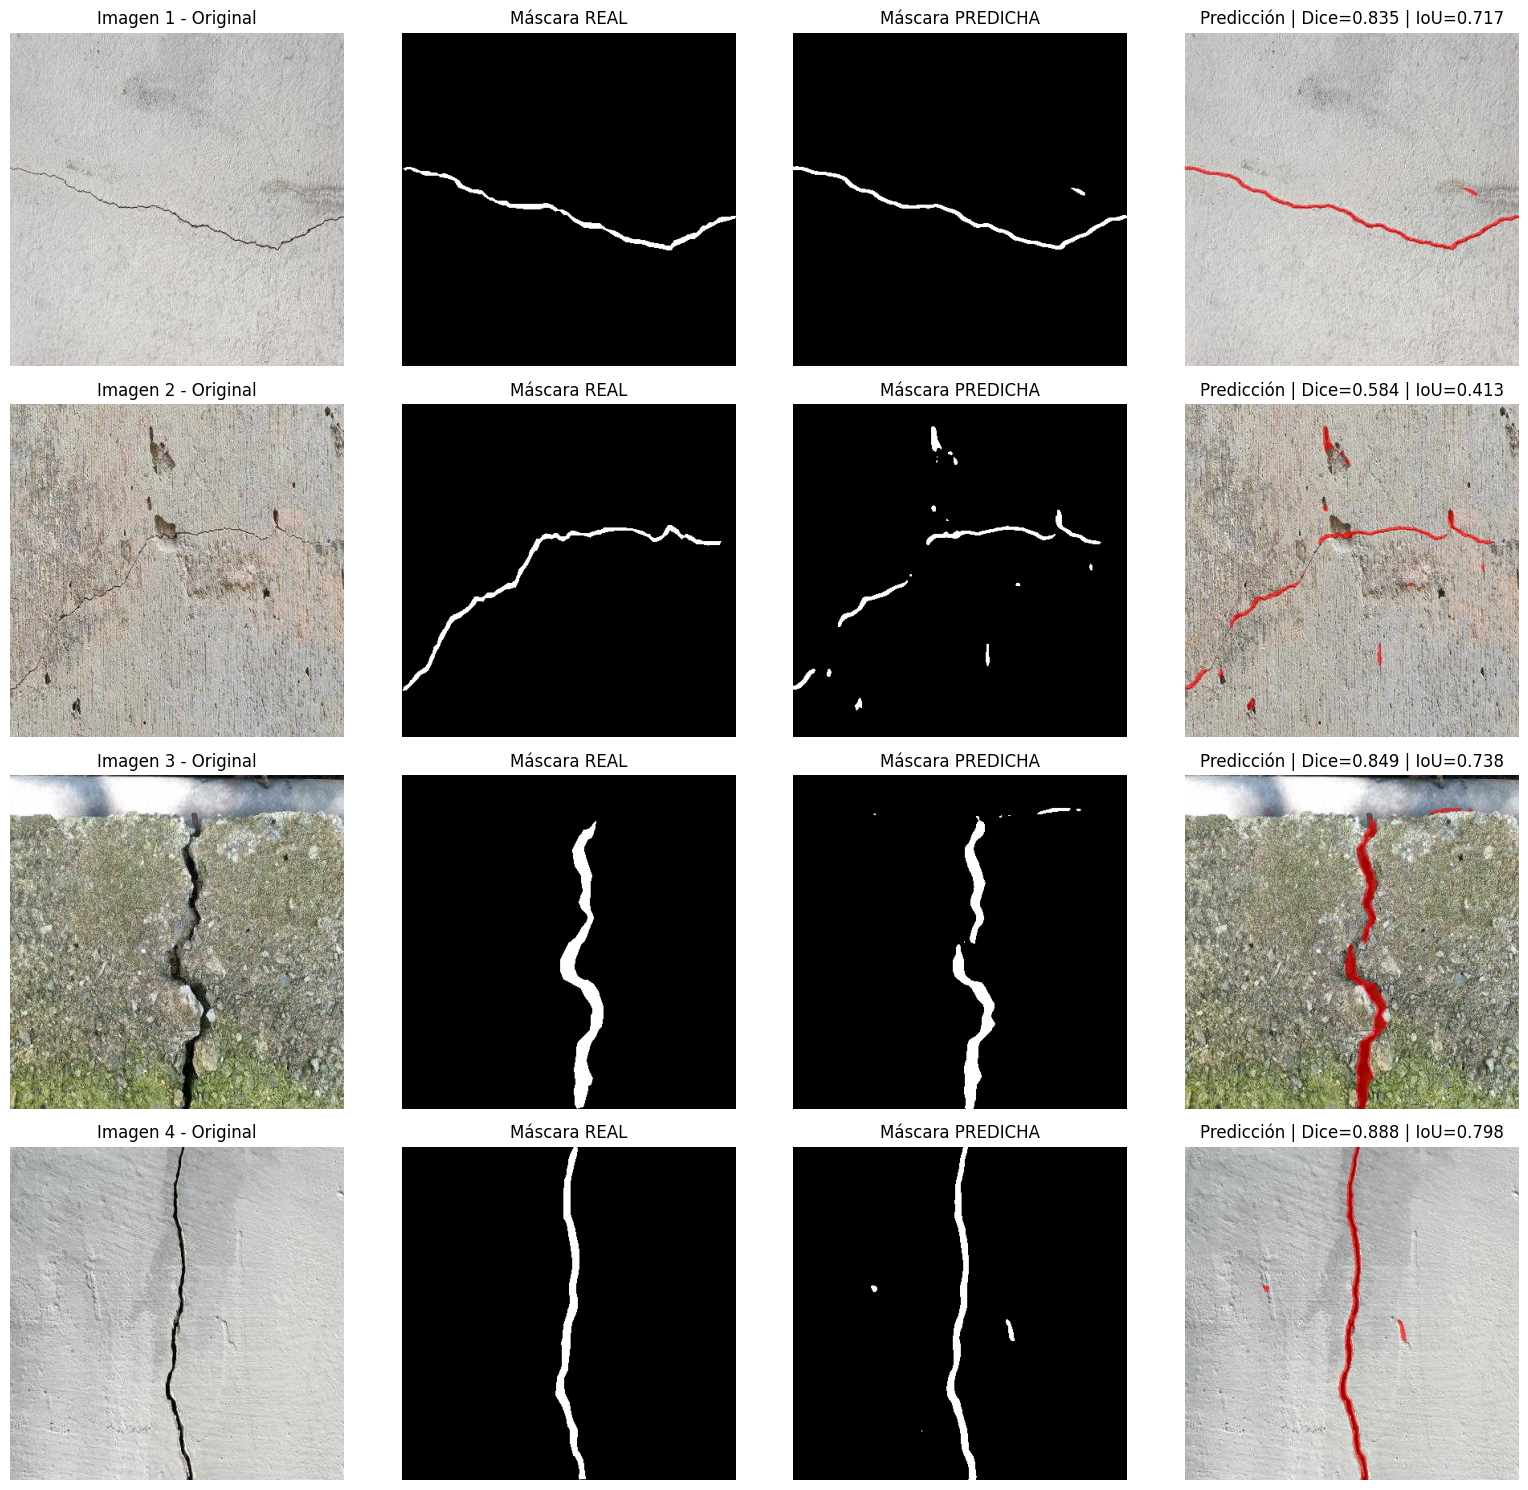

Estado: PASS - Predicciones visualizadas.


In [8]:
# ============================================================
# NB02 - CELDA 7: VISUALIZACIÓN DE PREDICCIONES DEL MODELO
#
# Objetivos:
#   1. Mostrar fotografías reales de VALIDACIÓN.
#   2. Comparar máscaras reales con máscaras predichas.
#   3. Resaltar las predicciones sobre las fotografías.
#   4. Calcular Dice e IoU individuales para cada imagen.
#
# IMPORTANTE:
#   - Usa el modelo BEST restaurado en la Celda 6.
#   - NO modifica pesos ni realiza entrenamiento.
#   - NO utiliza imágenes de TEST.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Trasladar los resultados de GPU a NumPy.
imagenes_np = imagenes_val.detach().cpu().numpy()
mascaras_np = mascaras_val.detach().cpu().numpy()
predicciones_np = predicciones_val.detach().cpu().numpy()

# Crear la figura: 4 imágenes x 4 representaciones.
fig, axes = plt.subplots(4, 4, figsize=(16, 15))

for i in range(4):

    # Imagen RGB: [C,H,W] -> [H,W,C].
    imagen = np.transpose(imagenes_np[i], (1, 2, 0))

    # Máscaras binarias: [1,H,W] -> [H,W].
    real = mascaras_np[i, 0]
    pred = predicciones_np[i, 0]

    # Cálculo de métricas por imagen.
    tp = np.logical_and(pred == 1, real == 1).sum()
    fp = np.logical_and(pred == 1, real == 0).sum()
    fn = np.logical_and(pred == 0, real == 1).sum()

    dice = 2 * tp / max(2 * tp + fp + fn, 1)
    iou = tp / max(tp + fp + fn, 1)

    # Superponer predicción en rojo.
    superpuesta = imagen.copy()
    zona_predicha = pred == 1

    superpuesta[zona_predicha] = (
        0.4 * superpuesta[zona_predicha]
        + 0.6 * np.array([1.0, 0.0, 0.0])
    )

    axes[i, 0].imshow(imagen)
    axes[i, 0].set_title(f"Imagen {i+1} - Original")

    axes[i, 1].imshow(real, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Máscara REAL")

    axes[i, 2].imshow(pred, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title("Máscara PREDICHA")

    axes[i, 3].imshow(superpuesta)
    axes[i, 3].set_title(
        f"Predicción | Dice={dice:.3f} | IoU={iou:.3f}"
    )

    for j in range(4):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

print("Estado: PASS - Predicciones visualizadas.")

Tabla resumen de métricas por imagen:



,Imagen,Dice,IoU,Observación
0,Imagen 1,0.835,0.717,Buena segmentación
1,Imagen 2,0.584,0.413,Segmentación irregular
2,Imagen 3,0.849,0.738,Buena segmentación
3,Imagen 4,0.888,0.798,Muy buena segmentación


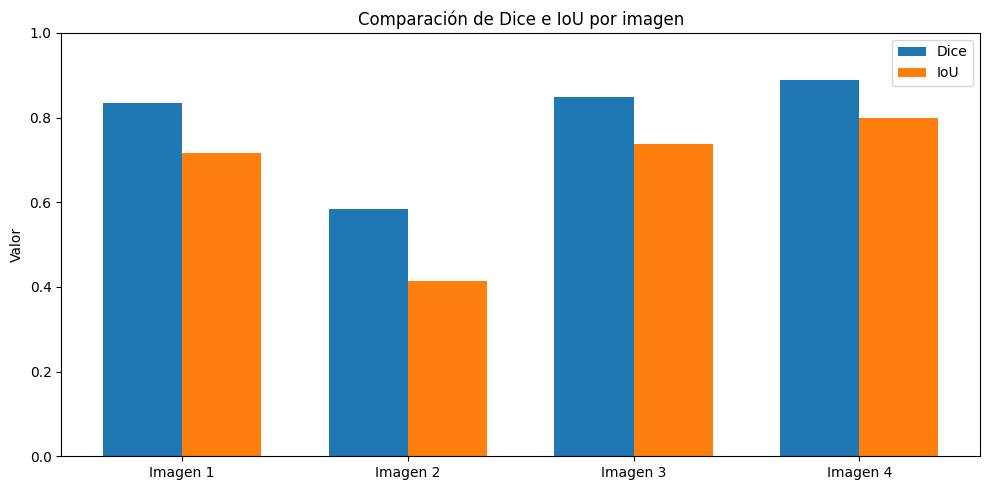

Estado: PASS - Tabla y gráfico generados.


In [9]:
# ============================================================
# NB02 - CELDA 8: TABLA RESUMEN Y GRÁFICO DE BARRAS
#
# Objetivos:
#   1. Construir una tabla con Dice e IoU para las 4 imágenes
#      mostradas en la Celda 7.
#   2. Añadir una observación breve por imagen.
#   3. Graficar Dice e IoU en barras.
#
# IMPORTANTE:
#   - Reutiliza las variables de la Celda 7:
#       imagenes_np, mascaras_np, predicciones_np
#   - No entrena ni modifica el modelo.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------------------------------------------
# 1. CALCULAR MÉTRICAS POR IMAGEN
# ------------------------------------------------------------

filas = []

for i in range(4):
    real = mascaras_np[i, 0]
    pred = predicciones_np[i, 0]

    tp = np.logical_and(pred == 1, real == 1).sum()
    fp = np.logical_and(pred == 1, real == 0).sum()
    fn = np.logical_and(pred == 0, real == 1).sum()

    dice = 2 * tp / max(2 * tp + fp + fn, 1)
    iou = tp / max(tp + fp + fn, 1)

    # Observación automática simple.
    if dice >= 0.85:
        observacion = "Muy buena segmentación"
    elif dice >= 0.75:
        observacion = "Buena segmentación"
    elif dice >= 0.60:
        observacion = "Aceptable, con algunos errores"
    else:
        observacion = "Segmentación irregular"

    filas.append({
        "Imagen": f"Imagen {i+1}",
        "Dice": round(dice, 3),
        "IoU": round(iou, 3),
        "Observación": observacion
    })

df_metricas = pd.DataFrame(filas)

# ------------------------------------------------------------
# 2. MOSTRAR TABLA
# ------------------------------------------------------------

print("Tabla resumen de métricas por imagen:\n")
display(df_metricas)

# ------------------------------------------------------------
# 3. GRAFICAR BARRAS DE DICE E IOU
# ------------------------------------------------------------

x = np.arange(len(df_metricas))
ancho = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - ancho/2, df_metricas["Dice"], width=ancho, label="Dice")
plt.bar(x + ancho/2, df_metricas["IoU"], width=ancho, label="IoU")

plt.xticks(x, df_metricas["Imagen"])
plt.ylim(0, 1.0)
plt.ylabel("Valor")
plt.title("Comparación de Dice e IoU por imagen")
plt.legend()
plt.tight_layout()
plt.show()

print("Estado: PASS - Tabla y gráfico generados.")

Carpeta de salida: /content/drive/MyDrive/Notebooks/Datasets/MIA-07_ExFinal_Fisuras/resultados/NB02_EncoderDecoder


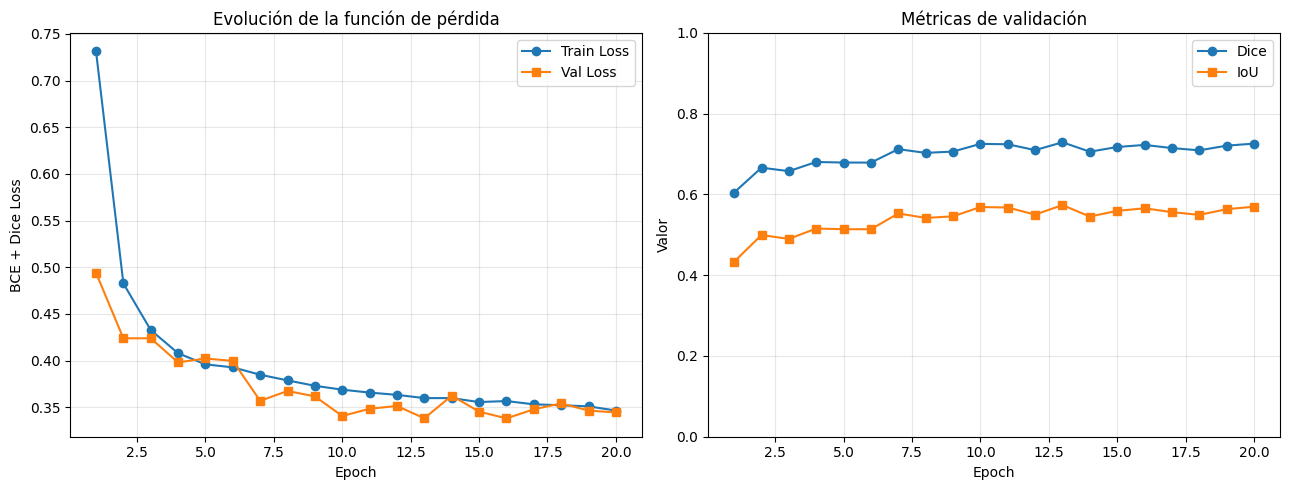

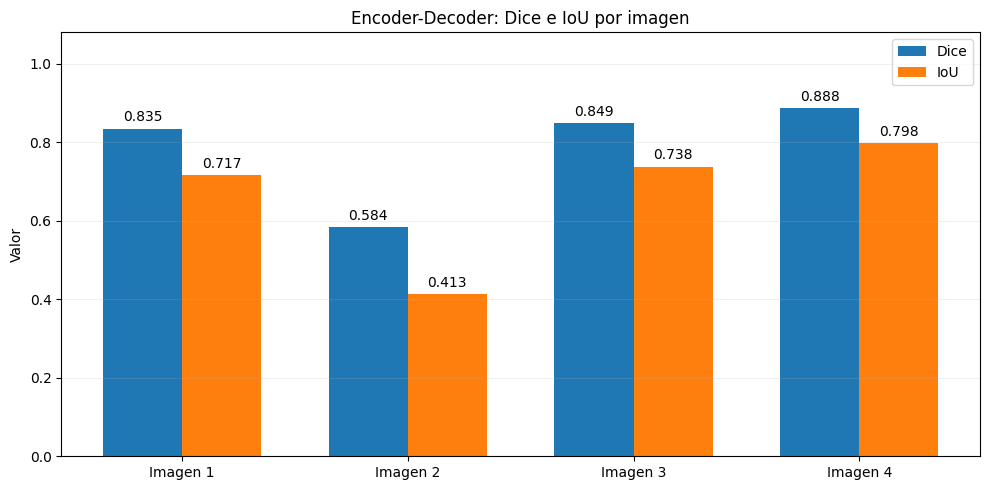

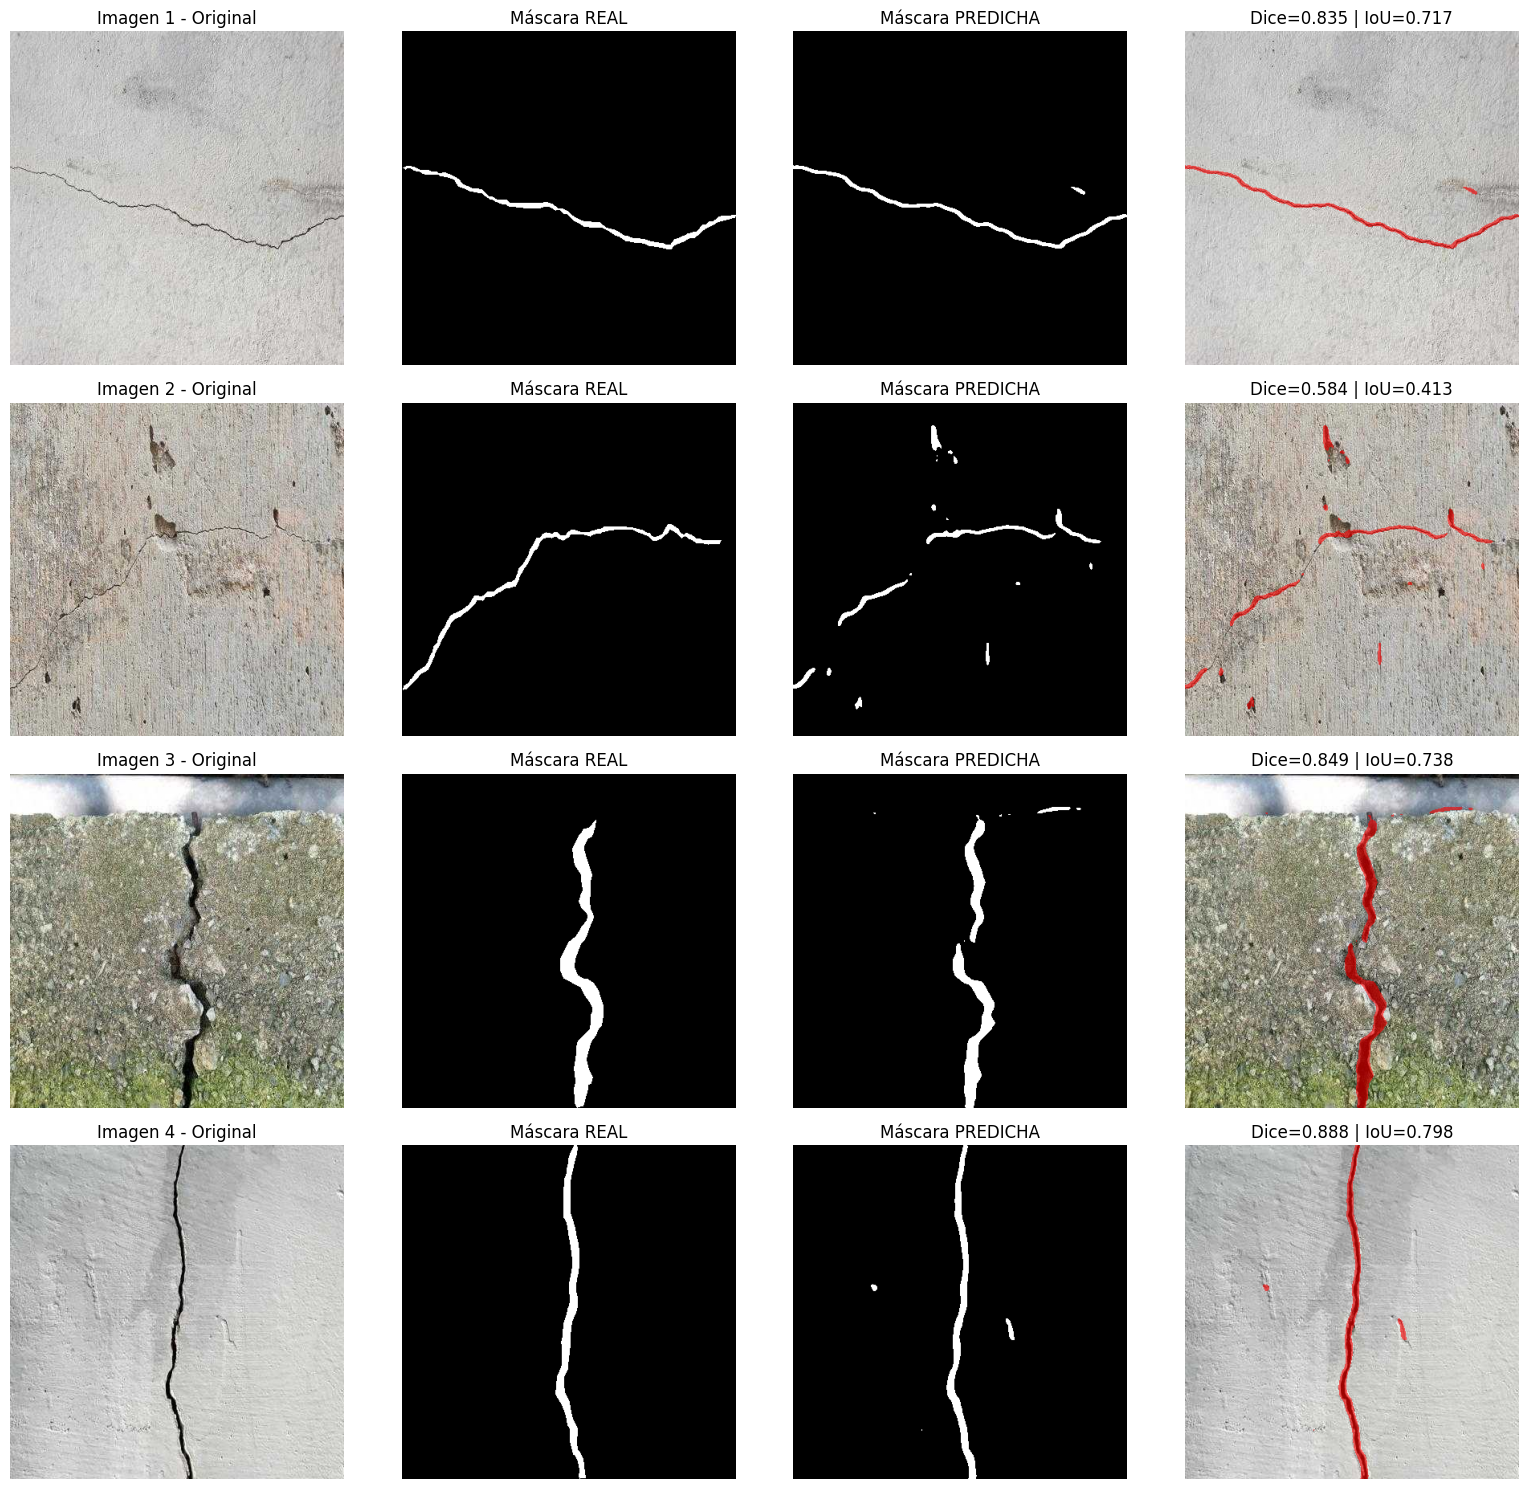


RESPALDO DE RESULTADOS NB02
OK | NB02_Historial_Entrenamiento.csv | 2.8 KB
OK | NB02_Metricas_4_Imagenes.csv | 0.2 KB
OK | NB02_Curvas_Entrenamiento.png | 110.1 KB
OK | NB02_Barras_4_Imagenes.png | 48.3 KB
OK | NB02_Predicciones_4_Imagenes.png | 2650.2 KB
OK | NB02_Resumen_Resultados.json | 1.0 KB

Estado: PASS - Resultados respaldados en Google Drive.


In [10]:
# ============================================================
# NB02 - CELDA 9: EXPORTACIÓN Y RESPALDO DE RESULTADOS
#
# Objetivos:
#   1. Guardar el historial de entrenamiento en CSV.
#   2. Guardar las métricas de las 4 imágenes en CSV.
#   3. Exportar las curvas Train/Val Loss y Dice/IoU.
#   4. Exportar el gráfico de barras de las 4 imágenes.
#   5. Exportar las predicciones visuales.
#   6. Crear un resumen JSON para el informe académico.
#
# IMPORTANTE:
#   - NO entrena ni modifica el modelo.
#   - NO utiliza imágenes de TEST.
#   - NO sobrescribe los checkpoints BEST y LAST.
# ============================================================

from pathlib import Path
from datetime import datetime
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. DEFINIR CARPETA DE RESULTADOS EN GOOGLE DRIVE
# ------------------------------------------------------------

carpeta_resultados = Path(
    "/content/drive/MyDrive/Notebooks/Datasets/"
    "MIA-07_ExFinal_Fisuras/resultados/NB02_EncoderDecoder"
)

carpeta_resultados.mkdir(parents=True, exist_ok=True)

# Comprobar que tenemos los datos necesarios.
assert len(historial) > 0, "No existe historial de entrenamiento."
assert len(df_metricas) == 4, "Falta la tabla de la Celda 8."
assert len(imagenes_np) >= 4, "Faltan imágenes de la Celda 7."

print("Carpeta de salida:", carpeta_resultados)

# ------------------------------------------------------------
# 2. EXPORTAR HISTORIAL COMPLETO DE ENTRENAMIENTO
# ------------------------------------------------------------

df_historial = pd.DataFrame(historial)

ruta_historial = (
    carpeta_resultados / "NB02_Historial_Entrenamiento.csv"
)

df_historial.to_csv(
    ruta_historial, index=False, encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 3. EXPORTAR TABLA DE LAS CUATRO IMÁGENES
# ------------------------------------------------------------

ruta_metricas = (
    carpeta_resultados / "NB02_Metricas_4_Imagenes.csv"
)

df_metricas.to_csv(
    ruta_metricas, index=False, encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 4. EXPORTAR CURVAS DE ENTRENAMIENTO Y VALIDACIÓN
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    df_historial["epoch"],
    df_historial["train_loss"],
    marker="o", label="Train Loss"
)

axes[0].plot(
    df_historial["epoch"],
    df_historial["val_loss"],
    marker="s", label="Val Loss"
)

axes[0].set_title("Evolución de la función de pérdida")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE + Dice Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    df_historial["epoch"],
    df_historial["val_dice"],
    marker="o", label="Dice"
)

axes[1].plot(
    df_historial["epoch"],
    df_historial["val_iou"],
    marker="s", label="IoU"
)

axes[1].set_title("Métricas de validación")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Valor")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.tight_layout()

ruta_curvas = (
    carpeta_resultados / "NB02_Curvas_Entrenamiento.png"
)

fig.savefig(ruta_curvas, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. EXPORTAR GRÁFICO DE BARRAS (CELDA 8)
# ------------------------------------------------------------

x = np.arange(len(df_metricas))
ancho = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

barras_dice = ax.bar(
    x - ancho / 2,
    df_metricas["Dice"],
    width=ancho,
    label="Dice"
)

barras_iou = ax.bar(
    x + ancho / 2,
    df_metricas["IoU"],
    width=ancho,
    label="IoU"
)

ax.bar_label(barras_dice, fmt="%.3f", padding=3)
ax.bar_label(barras_iou, fmt="%.3f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(df_metricas["Imagen"])
ax.set_ylim(0, 1.08)
ax.set_ylabel("Valor")
ax.set_title("Encoder-Decoder: Dice e IoU por imagen")
ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()

ruta_barras = (
    carpeta_resultados / "NB02_Barras_4_Imagenes.png"
)

fig.savefig(ruta_barras, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. EXPORTAR FIGURA DE PREDICCIONES (CELDA 7)
# ------------------------------------------------------------

fig, axes = plt.subplots(4, 4, figsize=(16, 15))

for i in range(4):

    imagen = np.transpose(imagenes_np[i], (1, 2, 0))
    real = mascaras_np[i, 0]
    pred = predicciones_np[i, 0]

    superpuesta = imagen.copy()
    zona = pred == 1

    superpuesta[zona] = (
        0.4 * superpuesta[zona]
        + 0.6 * np.array([1.0, 0.0, 0.0])
    )

    axes[i, 0].imshow(imagen)
    axes[i, 0].set_title(f"Imagen {i+1} - Original")

    axes[i, 1].imshow(real, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Máscara REAL")

    axes[i, 2].imshow(pred, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title("Máscara PREDICHA")

    axes[i, 3].imshow(superpuesta)
    axes[i, 3].set_title(
        f"Dice={df_metricas.iloc[i]['Dice']:.3f} | "
        f"IoU={df_metricas.iloc[i]['IoU']:.3f}"
    )

    for j in range(4):
        axes[i, j].axis("off")

fig.tight_layout()

ruta_predicciones = (
    carpeta_resultados / "NB02_Predicciones_4_Imagenes.png"
)

fig.savefig(ruta_predicciones, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. CREAR RESUMEN JSON
# ------------------------------------------------------------

# Mejor registro según la regla MIN_DELTA del entrenamiento.
epoch_best = estado_best["epoch"]

registro_best = next(
    r for r in historial
    if r["epoch"] == epoch_best
)

# Guardar también la epoch de menor pérdida numérica.
registro_minimo = min(
    historial,
    key=lambda r: r["val_loss"]
)

resumen = {
    "fecha_exportacion": datetime.now().isoformat(),
    "notebook": "NB02_EncoderDecoder",
    "arquitectura": "EncoderDecoder_sin_skip",
    "parametros_entrenables": 106753,
    "dataset": "Crack-Seg completo v1",
    "imagenes_train": 3717,
    "imagenes_val": 199,
    "imagenes_test_reservadas": 111,
    "resolucion": [416, 416],
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "loss": "BCE + Dice",
    "optimizer": "Adam",
    "early_stopping_patience": PATIENCE,
    "min_delta": MIN_DELTA,
    "epochs_ejecutadas": len(historial),
    "epoch_checkpoint_best": epoch_best,
    "checkpoint_best": {
        "train_loss": registro_best["train_loss"],
        "val_loss": registro_best["val_loss"],
        "val_dice": registro_best["val_dice"],
        "val_iou": registro_best["val_iou"]
    },
    "epoch_minima_val_loss_observada": registro_minimo["epoch"],
    "tiempo_total_epochs_seg": tiempo_acumulado,
    "metricas": "Validación; no son resultados de TEST",
    "checkpoints": [
        "checkpoint_best.pt",
        "checkpoint_last.pt"
    ]
}

ruta_resumen = (
    carpeta_resultados / "NB02_Resumen_Resultados.json"
)

with open(ruta_resumen, "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=4, ensure_ascii=False)

# ------------------------------------------------------------
# 8. VERIFICAR ARCHIVOS GENERADOS
# ------------------------------------------------------------

archivos_generados = [
    ruta_historial,
    ruta_metricas,
    ruta_curvas,
    ruta_barras,
    ruta_predicciones,
    ruta_resumen
]

print("\n" + "=" * 65)
print("RESPALDO DE RESULTADOS NB02")
print("=" * 65)

for archivo in archivos_generados:
    assert archivo.is_file()
    assert archivo.stat().st_size > 0

    print(
        f"OK | {archivo.name} | "
        f"{archivo.stat().st_size / 1024:.1f} KB"
    )

print("\nEstado: PASS - Resultados respaldados en Google Drive.")